# 4xResol_SiemensStar_NoScinti Resolution Position Finder

Use this notebook to collect the summed raw-pixel TIFFs from `4xResol_SiemensStar_NoScinti` resolution-pattern runs and rank the positions by image sharpness/resolution.

The scoring is designed for a Siemens-star style pattern with dark radial lines. It samples the pattern in polar coordinates and ranks images by angular line modulation, with a secondary Laplacian sharpness score as a sanity check.


## 1. Settings

Set `INPUT_ROOT` to the folder that contains the `4xResol_SiemensStar_NoScinti` experiment folders. If you make a new folder and drop all `4xResol_SiemensStar_NoScinti` folders into it, point `INPUT_ROOT` to that folder.

The notebook looks first for raw pixel activation sums (`pixelActivations_sum`). If those are not present, change `TIFF_NAME_PATTERNS` to match the files you want to analyze.


In [158]:
from pathlib import Path

# Folder containing the 4xResol_SiemensStar_NoScinti experiment folders.
# /data01/data was mentioned, but on this machine the current acquisition data is under /data01/data_acquisition/data.
INPUT_ROOT = Path('/data01/data_acquisition/data')

# Where selected TIFFs can be copied or symlinked for a clean working set.
WORK_FOLDER = Path('/data01/software/toolbox/image analysis/4xResol_SiemensStar_NoScinti_resolution_tiffs')

FOLDER_NAME_CONTAINS = '4xResol_SiemensStar_NoScinti'
TIFF_NAME_PATTERNS = (
    '*pixelActivations_sum*.tif*',      # summed raw-pixel activation TIFFs
    '*raw*pixel*.tif*',                # fallback naming pattern
)

# If a top-level *_sumAllRuns.tiff exists for a position, use it and ignore per-run copies for that position.
PREFER_SUM_ALL_RUNS = True

# File collection behavior. Set COLLECT_FILES=True after checking the discovery table.
COLLECT_FILES = False
COLLECT_MODE = 'copy'  # 'copy' or 'symlink'
OVERWRITE_COLLECTED_FILES = False

# Analysis region.
# CENTER_GUESS_XY gives the automatic finder a starting point in (x, y) pixels.
# CENTER_XY fixes the center exactly and disables automatic refinement.
CENTER_GUESS_XY = (80, 120)  # example: (512, 384)
CENTER_XY = (100, 116)       # example: (512, 384)
CENTER_SEARCH_RADIUS_PX = 80

# Radial annulus used for scoring, in pixels from the pattern center.
# Keep the inner radius outside the unresolved center dot/noisy core.
RADIUS_MIN_PX = 15
RADIUS_MAX_PX = None  # None means 45% of the shortest image dimension
N_RADII = 80
N_ANGLES = 720

# If the pattern is much smaller than the image, crop analysis by setting MAX_ANALYSIS_RADIUS_PX.
MAX_ANALYSIS_RADIUS_PX = None

TOP_N_TO_SHOW = 6

# Large visual gallery for checking clarity by eye.
VISUAL_SORT_BY = 'score'       # 'score' or 'position'
VISUAL_IMAGES_PER_ROW = 2
VISUAL_IMAGE_SIZE_IN = 6.5
VISUAL_ZOOM_RADIUS_PX = None   # example: 120; None shows the full image
SHOW_CENTER_OVERLAY = True

## 2. Imports and Helpers

In [159]:
import math
import re
import shutil
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import exposure, filters

pd.set_option('display.max_colwidth', 160)
plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['image.cmap'] = 'gray'

In [160]:
def read_tiff_2d(path):
    """Read a TIFF and return a 2D float32 image.

    If the TIFF is a stack or color image, reduce it conservatively to one grayscale image.
    """
    arr = tifffile.imread(str(path))
    arr = np.asarray(arr)
    if arr.ndim == 2:
        img = arr
    elif arr.ndim == 3 and arr.shape[-1] in (3, 4):
        img = arr[..., :3].mean(axis=-1)
    elif arr.ndim == 3:
        img = arr.sum(axis=0)
    else:
        raise ValueError(f'Unsupported TIFF shape {arr.shape} for {path}')
    return img.astype(np.float32, copy=False)


def robust_normalize(img, p_low=1, p_high=99.8):
    img = np.asarray(img, dtype=np.float32)
    finite = np.isfinite(img)
    if not finite.any():
        return np.zeros_like(img, dtype=np.float32)
    lo, hi = np.percentile(img[finite], [p_low, p_high])
    if not np.isfinite(hi - lo) or hi <= lo:
        lo, hi = float(np.nanmin(img)), float(np.nanmax(img))
    if hi <= lo:
        return np.zeros_like(img, dtype=np.float32)
    return np.clip((img - lo) / (hi - lo), 0, 1).astype(np.float32)


def path_contains_token(path, token):
    token = token.lower()
    return any(token in part.lower() for part in Path(path).parts)


def infer_experiment_name(path, token=FOLDER_NAME_CONTAINS):
    token_l = token.lower()
    parts = Path(path).parts
    matches = [part for part in parts if token_l in part.lower()]
    if matches:
        # Use the first matching folder, not the file name.
        for part in matches:
            if not part.lower().endswith(('.tif', '.tiff')):
                return part
    return Path(path).parent.name


def infer_position_label(path):
    text = str(path)
    # Prefer explicit focus labels in folder/file names, e.g. focus0205m or focusm0320_new.
    m = re.search(r'(focus[mp]?\d+(?:[_-]?[A-Za-z]+)?)', text, flags=re.IGNORECASE)
    if m:
        return m.group(1).strip('_-')

    # Common pattern: exp401_ResolPattern_4xResol_SiemensStar_NoScinti_0265m_00000 or ..._4xResol_SiemensStar_NoScinti_0265m/...
    m = re.search(r'4xResol_SiemensStar_NoScinti[_-]([^_/\\]+)', text, flags=re.IGNORECASE)
    if m:
        return m.group(1)
    # Fallbacks for focus-style names.
    m = re.search(r'(?:focus|pos|position)[_-]?([+-]?[a-zA-Z0-9.]+)', text, flags=re.IGNORECASE)
    if m:
        return m.group(1)
    return Path(path).stem


def natural_key(value):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', str(value))]


def natural_sort_text(value):
    def repl(match):
        return f'{int(match.group()):012d}'
    return re.sub(r'\d+', repl, str(value).lower())


def safe_name(text):
    text = re.sub(r'[^A-Za-z0-9_.+-]+', '_', str(text))
    return text.strip('_') or 'unnamed'



def concise_image_label(row):
    """Return a short human label for figure titles, preferring unique filename parts."""
    path = Path(row.get('path', row.get('source_path', '')))
    filename = str(row.get('filename', path.name))
    position = str(row.get('position_label', '')).strip()
    text = ' '.join([position, filename, str(path)])

    patterns = [
        r'(focus[mp]?\d+(?:[_-]?[A-Za-z]+)?)',
        r'(pos(?:ition)?[_-]?\d+[A-Za-z]*)',
        r'(\d{4}m)',
        r'(\d{3,5}(?:um|mm|m))',
    ]
    for pattern in patterns:
        match = re.search(pattern, text, flags=re.IGNORECASE)
        if match:
            return match.group(1).strip('_-')

    if position and position.lower() not in {'nan', 'none'}:
        return position

    stem = Path(filename).stem
    stem = re.sub(r'_pixelActivations_sum(?:AllRuns)?$', '', stem, flags=re.IGNORECASE)
    stem = re.sub(r'_sumImage_.*$', '', stem, flags=re.IGNORECASE)
    return stem


def discover_tiffs(input_root=INPUT_ROOT, patterns=TIFF_NAME_PATTERNS, folder_token=FOLDER_NAME_CONTAINS, prefer_sum_all_runs=PREFER_SUM_ALL_RUNS):
    input_root = Path(input_root)
    if not input_root.exists():
        raise FileNotFoundError(f'INPUT_ROOT does not exist: {input_root}')

    paths = []
    for pattern in patterns:
        paths.extend(input_root.rglob(pattern))
    paths = sorted(set(p for p in paths if p.is_file() and path_contains_token(p, folder_token)), key=lambda p: natural_key(str(p)))

    rows = []
    for p in paths:
        experiment = infer_experiment_name(p, folder_token)
        rows.append({
            'source_path': p,
            'filename': p.name,
            'experiment': experiment,
            'position_label': infer_position_label(p),
            'is_sum_all_runs': 'sumallruns' in p.name.lower(),
            'is_pixel_sum': 'pixelactivations_sum' in p.name.lower(),
            'size_mb': p.stat().st_size / 1024**2,
        })
    df = pd.DataFrame(rows)
    if df.empty:
        return df

    if prefer_sum_all_runs:
        keep = []
        for _, group in df.groupby('experiment', sort=False):
            sum_all = group[group['is_sum_all_runs']]
            keep.append(sum_all if not sum_all.empty else group)
        df = pd.concat(keep, ignore_index=True)

    df = df.sort_values(['position_label', 'filename'], key=lambda s: s.map(natural_sort_text)).reset_index(drop=True)
    return df


def collect_tiffs(df, dest=WORK_FOLDER, mode=COLLECT_MODE, overwrite=OVERWRITE_COLLECTED_FILES):
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    collected = []
    for _, row in df.iterrows():
        src = Path(row['source_path'])
        out_name = f"{safe_name(row['position_label'])}__{safe_name(row['experiment'])}__{safe_name(src.name)}"
        dst = dest / out_name
        if dst.exists() or dst.is_symlink():
            if overwrite:
                dst.unlink()
            else:
                collected.append(dst)
                continue
        if mode == 'copy':
            shutil.copy2(src, dst)
        elif mode == 'symlink':
            dst.symlink_to(src)
        else:
            raise ValueError("mode must be 'copy' or 'symlink'")
        collected.append(dst)
    return collected


## 3. Discover and Optionally Collect TIFFs

Run the next cell first and inspect the table. If the selected files look correct, set `COLLECT_FILES = True` in the settings cell and rerun this section.


In [161]:
discovered = discover_tiffs()
print(f'Discovered {len(discovered)} TIFF file(s).')

discovered[['position_label', 'experiment', 'filename', 'is_sum_all_runs', 'is_pixel_sum', 'size_mb', 'source_path']]

Discovered 9 TIFF file(s).


,position_label,experiment,filename,is_sum_all_runs,is_pixel_sum,size_mb,source_path
0,focus0045m,focus0045m_4xResol_SiemensStar_NoScinti,focus0045m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0045m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0045m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
1,focus0065m,focus0065m_4xResol_SiemensStar_NoScinti,focus0065m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0065m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0065m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
2,focus0075m,focus0075m_4xResol_SiemensStar_NoScinti,focus0075m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0075m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0075m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
3,focus0080m,focus0080m_4xResol_SiemensStar_NoScinti,focus0080m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0080m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0080m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
4,focus0085m,focus0085m_4xResol_SiemensStar_NoScinti,focus0085m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0085m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0085m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
5,focus0090m,focus0090m_4xResol_SiemensStar_NoScinti,focus0090m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0090m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0090m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
6,focus0095m,focus0095m_4xResol_SiemensStar_NoScinti,focus0095m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0095m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0095m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
7,focus0105m,focus0105m_4xResol_SiemensStar_NoScinti,focus0105m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0105m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0105m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
8,focus0125m,focus0125m_4xResol_SiemensStar_NoScinti,focus0125m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,True,True,0.250366,/data01/data_acquisition/data/focus0125m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0125m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff


In [162]:
if COLLECT_FILES:
    collected_paths = collect_tiffs(discovered)
    print(f'Collected {len(collected_paths)} file(s) into {WORK_FOLDER}')
    image_paths = collected_paths
else:
    print('COLLECT_FILES is False; analyzing files in place.')
    image_paths = list(discovered['source_path']) if not discovered.empty else []

image_paths[:5]

COLLECT_FILES is False; analyzing files in place.


[PosixPath('/data01/data_acquisition/data/focus0045m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0045m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff'),
 PosixPath('/data01/data_acquisition/data/focus0065m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0065m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff'),
 PosixPath('/data01/data_acquisition/data/focus0075m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0075m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff'),
 PosixPath('/data01/data_acquisition/data/focus0080m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0080m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff'),
 PosixPath('/data01/data_acquisition/data/focus0085m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0085m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff')]

## 4. Preview Images and Center

The automatic center finder assumes the radial pattern is near the image center unless `CENTER_GUESS_XY` is set. If the overlay is wrong, set `CENTER_GUESS_XY = (x, y)` in the settings cell and rerun from here. Use `CENTER_XY = (x, y)` only when you want to force an exact center with no automatic refinement.


Using manual center: x=100.0, y=116.0
Analysis radius: 15.0 to 90.0 px


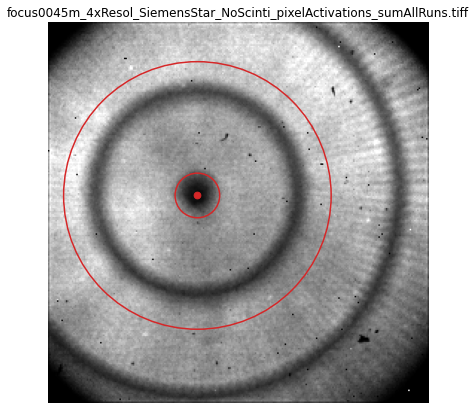

In [163]:
def sample_polar(img, center_xy, radii, angles):
    cx, cy = center_xy
    rr, tt = np.meshgrid(radii, angles, indexing='ij')
    xs = cx + rr * np.cos(tt)
    ys = cy + rr * np.sin(tt)
    coords = np.vstack([ys.ravel(), xs.ravel()])
    sampled = ndi.map_coordinates(img, coords, order=1, mode='nearest')
    return sampled.reshape(len(radii), len(angles))


def center_score(img_norm, center_xy, radii, angles):
    # Dark radial lines become bright after inversion.
    inv = 1.0 - img_norm
    polar = sample_polar(inv, center_xy, radii, angles)
    profile = np.nanmedian(polar, axis=0)
    profile = profile - ndi.gaussian_filter1d(profile, sigma=10, mode='wrap')
    scale = np.nanmedian(np.abs(profile)) + 1e-6
    return float(np.nanstd(profile) / scale)


def estimate_center(img, guess_xy=None, search_radius_px=CENTER_SEARCH_RADIUS_PX, step_px=8):
    img_norm = robust_normalize(img)
    h, w = img_norm.shape
    if guess_xy is None:
        base = (w / 2, h / 2)
    else:
        gx, gy = guess_xy
        base = (float(np.clip(gx, 0, w - 1)), float(np.clip(gy, 0, h - 1)))
    max_r = min(h, w) * 0.45
    radii = np.linspace(max(20, max_r * 0.20), max(30, max_r * 0.55), 50)
    angles = np.linspace(0, 2 * np.pi, 360, endpoint=False)

    best_xy = base
    best = -np.inf
    for spacing in (step_px, max(2, step_px // 2), 1):
        cx0, cy0 = best_xy
        candidates_x = np.arange(cx0 - spacing * 4, cx0 + spacing * 4 + 0.1, spacing)
        candidates_y = np.arange(cy0 - spacing * 4, cy0 + spacing * 4 + 0.1, spacing)
        if spacing == step_px:
            candidates_x = np.arange(base[0] - search_radius_px, base[0] + search_radius_px + 0.1, spacing)
            candidates_y = np.arange(base[1] - search_radius_px, base[1] + search_radius_px + 0.1, spacing)
        for cx in candidates_x:
            if cx < 0 or cx >= w:
                continue
            for cy in candidates_y:
                if cy < 0 or cy >= h:
                    continue
                score = center_score(img_norm, (cx, cy), radii, angles)
                if score > best:
                    best = score
                    best_xy = (float(cx), float(cy))
    return best_xy, best


def default_radius_max(img_shape, center_xy):
    h, w = img_shape
    cx, cy = center_xy
    edge_limit = min(cx, cy, w - 1 - cx, h - 1 - cy)
    radius_max = edge_limit * 0.9
    if MAX_ANALYSIS_RADIUS_PX is not None:
        radius_max = min(radius_max, MAX_ANALYSIS_RADIUS_PX)
    if RADIUS_MAX_PX is not None:
        radius_max = min(radius_max, RADIUS_MAX_PX)
    return max(radius_max, RADIUS_MIN_PX + 5)


if not image_paths:
    raise RuntimeError('No image paths are available. Check INPUT_ROOT and TIFF_NAME_PATTERNS.')

first_img = read_tiff_2d(image_paths[0])
if CENTER_XY is not None:
    center_xy = tuple(CENTER_XY)
    print(f'Using manual center: x={center_xy[0]:.1f}, y={center_xy[1]:.1f}')
else:
    center_xy, center_quality = estimate_center(first_img, guess_xy=CENTER_GUESS_XY)
    if CENTER_GUESS_XY is None:
        print(f'Estimated center: x={center_xy[0]:.1f}, y={center_xy[1]:.1f}; center quality={center_quality:.2f}')
    else:
        print(f'Refined center from guess {CENTER_GUESS_XY}: x={center_xy[0]:.1f}, y={center_xy[1]:.1f}; center quality={center_quality:.2f}')

radius_max = default_radius_max(first_img.shape, center_xy)
print(f'Analysis radius: {RADIUS_MIN_PX:.1f} to {radius_max:.1f} px')

fig, ax = plt.subplots(figsize=(7, 7))
show = robust_normalize(first_img)
ax.imshow(show, vmin=0, vmax=1)
ax.scatter([center_xy[0]], [center_xy[1]], c='tab:red', s=45)
for r in [RADIUS_MIN_PX, radius_max]:
    ax.add_patch(plt.Circle(center_xy, r, fill=False, color='tab:red', linewidth=1.5))
ax.set_title(Path(image_paths[0]).name)
ax.set_axis_off()
plt.show()


## 5. Score Resolution/Focus

`radial_score` measures how strongly dark radial lines remain separated in the annulus. The weighting emphasizes smaller radii because a sharper setup preserves contrast closer to the center of a radial resolution pattern.

`laplacian_score` is a general edge-sharpness cross-check within the same annulus.


In [164]:
def annulus_mask(shape, center_xy, radius_min, radius_max):
    h, w = shape
    y, x = np.ogrid[:h, :w]
    r = np.sqrt((x - center_xy[0])**2 + (y - center_xy[1])**2)
    return (r >= radius_min) & (r <= radius_max)


def angular_contrast_by_radius(img_norm, center_xy, radius_min=RADIUS_MIN_PX, radius_max=None, n_radii=N_RADII, n_angles=N_ANGLES):
    if radius_max is None:
        radius_max = default_radius_max(img_norm.shape, center_xy)
    radii = np.linspace(radius_min, radius_max, n_radii)
    angles = np.linspace(0, 2 * np.pi, n_angles, endpoint=False)
    polar = sample_polar(img_norm, center_xy, radii, angles)

    # Remove slow illumination changes around the ring while preserving line-to-line modulation.
    detrended = polar - ndi.gaussian_filter1d(polar, sigma=max(3, n_angles // 48), axis=1, mode='wrap')
    robust_amp = np.nanpercentile(detrended, 95, axis=1) - np.nanpercentile(detrended, 5, axis=1)
    local_scale = np.nanpercentile(polar, 95, axis=1) - np.nanpercentile(polar, 5, axis=1)
    contrast = robust_amp / (local_scale + 1e-6)
    return radii, contrast


def score_image(path, center_xy=center_xy):
    img = read_tiff_2d(path)
    img_norm = robust_normalize(img)
    radius_max = default_radius_max(img_norm.shape, center_xy)
    radii, contrast = angular_contrast_by_radius(img_norm, center_xy, radius_max=radius_max)

    weights = 1 / np.sqrt(np.maximum(radii, 1))
    radial_score = float(np.average(contrast, weights=weights))

    mask = annulus_mask(img_norm.shape, center_xy, RADIUS_MIN_PX, radius_max)
    lap = ndi.laplace(img_norm)
    laplacian_score = float(np.nanvar(lap[mask]))
    sobel_score = float(np.nanmean(filters.sobel(img_norm)[mask]))

    return {
        'path': Path(path),
        'filename': Path(path).name,
        'position_label': infer_position_label(path),
        'radial_score': radial_score,
        'laplacian_score': laplacian_score,
        'sobel_score': sobel_score,
        'radius_max_px': radius_max,
        'radii': radii,
        'contrast': contrast,
    }


def minmax(series):
    s = pd.Series(series, dtype=float)
    lo, hi = s.min(), s.max()
    if not np.isfinite(hi - lo) or hi == lo:
        return pd.Series(np.ones(len(s)), index=s.index)
    return (s - lo) / (hi - lo)

results = []
for path in image_paths:
    try:
        results.append(score_image(path))
    except Exception as exc:
        print(f'Failed on {path}: {exc}')

results_df = pd.DataFrame(results)
results_df['radial_norm'] = minmax(results_df['radial_score'])
results_df['laplacian_norm'] = minmax(results_df['laplacian_score'])
results_df['sobel_norm'] = minmax(results_df['sobel_score'])
results_df['combined_score'] = 0.70 * results_df['radial_norm'] + 0.20 * results_df['laplacian_norm'] + 0.10 * results_df['sobel_norm']
results_df = results_df.sort_values('combined_score', ascending=False).reset_index(drop=True)

summary_cols = ['position_label', 'combined_score', 'radial_score', 'laplacian_score', 'sobel_score', 'filename', 'path']
results_df[summary_cols]


,position_label,combined_score,radial_score,laplacian_score,sobel_score,filename,path
0,focus0085m,0.980114,0.502072,0.046650,0.093985,focus0085m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0085m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0085m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
1,focus0080m,0.946515,0.508146,0.039966,0.089357,focus0080m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0080m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0080m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
2,focus0090m,0.732907,0.464434,0.031653,0.081654,focus0090m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0090m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0090m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
3,focus0125m,0.627304,0.431588,0.037739,0.063096,focus0125m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0125m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0125m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
4,focus0075m,0.549227,0.436463,0.021201,0.070286,focus0075m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0075m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0075m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
5,focus0065m,0.223436,0.351788,0.018069,0.056658,focus0065m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0065m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0065m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
6,focus0095m,0.187495,0.343957,0.016250,0.057465,focus0095m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0095m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0095m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
7,focus0045m,0.082993,0.315535,0.018305,0.045306,focus0045m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0045m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0045m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
8,focus0105m,0.022415,0.294312,0.017560,0.052023,focus0105m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/focus0105m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0105m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff


In [165]:
best = results_df.iloc[0]
print('Best candidate')
print(f"  position: {best['position_label']}")
print(f"  file:     {best['path']}")
print(f"  score:    {best['combined_score']:.3f}")

Best candidate
  position: focus0085m
  file:     /data01/data_acquisition/data/focus0085m_4xResol_SiemensStar_NoScinti/pixelTiffFiles/focus0085m_4xResol_SiemensStar_NoScinti_pixelActivations_sumAllRuns.tiff
  score:    0.980


## 6. Inspect Rankings

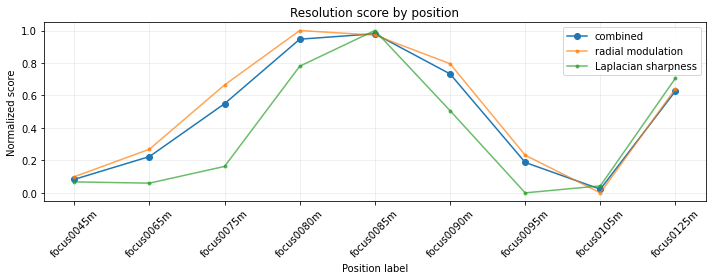

In [166]:
plot_df = results_df.copy()
plot_df = plot_df.sort_values('position_label', key=lambda s: s.map(natural_sort_text))

x_labels = plot_df['position_label'].astype(str).to_list()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x_labels, plot_df['combined_score'].to_numpy(), marker='o', label='combined')
ax.plot(x_labels, plot_df['radial_norm'].to_numpy(), marker='.', alpha=0.7, label='radial modulation')
ax.plot(x_labels, plot_df['laplacian_norm'].to_numpy(), marker='.', alpha=0.7, label='Laplacian sharpness')
ax.set_xlabel('Position label')
ax.set_ylabel('Normalized score')
ax.set_title('Resolution score by position')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


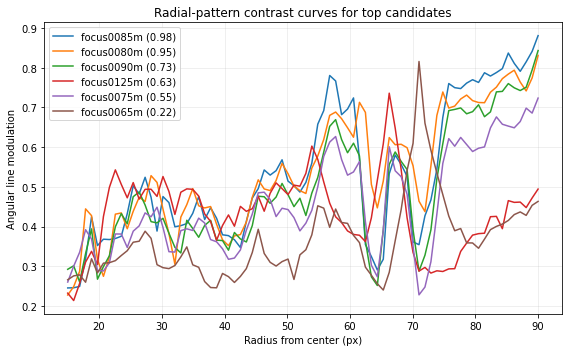

In [167]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in results_df.head(min(TOP_N_TO_SHOW, len(results_df))).iterrows():
    ax.plot(row['radii'], row['contrast'], label=f"{row['position_label']} ({row['combined_score']:.2f})")
ax.set_xlabel('Radius from center (px)')
ax.set_ylabel('Angular line modulation')
ax.set_title('Radial-pattern contrast curves for top candidates')
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


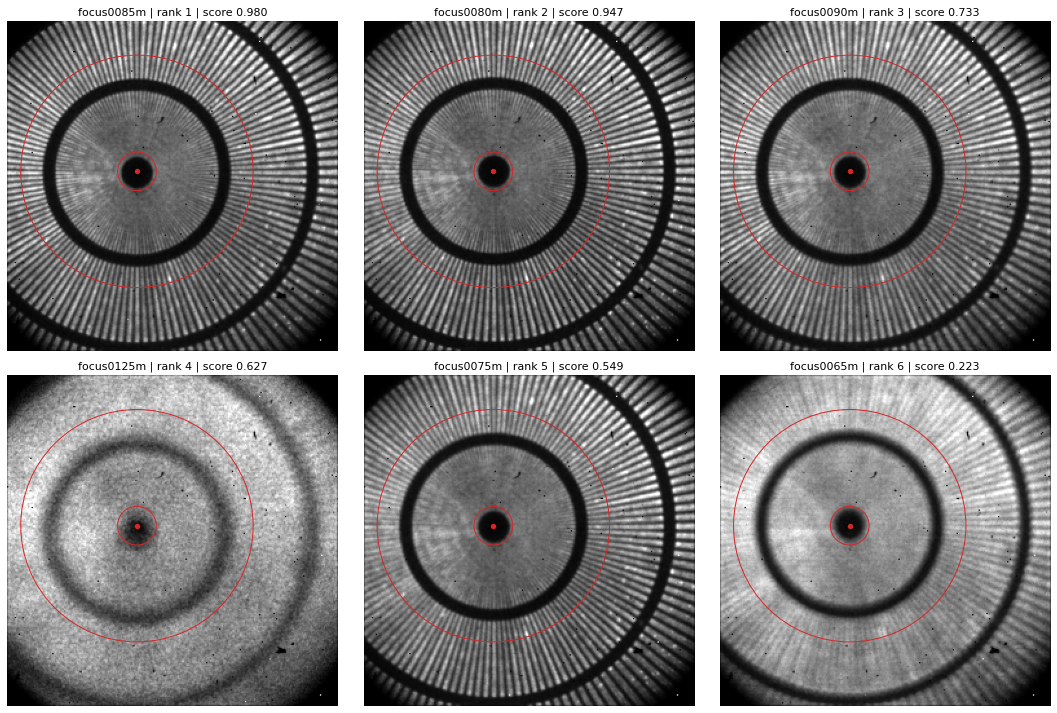

In [168]:
def show_ranked_images(df, n=TOP_N_TO_SHOW, center_xy=center_xy):
    n = min(n, len(df))
    cols = min(3, n)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.set_axis_off()
    for ax, (_, row) in zip(axes.ravel(), df.head(n).iterrows()):
        img = read_tiff_2d(row['path'])
        img_norm = robust_normalize(img)
        ax.imshow(img_norm, vmin=0, vmax=1)
        ax.scatter([center_xy[0]], [center_xy[1]], c='tab:red', s=20)
        ax.add_patch(plt.Circle(center_xy, RADIUS_MIN_PX, fill=False, color='tab:red', linewidth=1.0))
        ax.add_patch(plt.Circle(center_xy, row['radius_max_px'], fill=False, color='tab:red', linewidth=1.0))
        label = concise_image_label(row)
        ax.set_title(f"{label} | rank {row.name + 1} | score {row['combined_score']:.3f}", fontsize=11)
    fig.tight_layout()
    plt.show()

show_ranked_images(results_df)


## 7. Visual Check: Large Image Gallery

Use this section to compare the resolution patterns by eye. The default view sorts by algorithm score and displays large images. Change `VISUAL_SORT_BY`, `VISUAL_IMAGES_PER_ROW`, `VISUAL_IMAGE_SIZE_IN`, or `VISUAL_ZOOM_RADIUS_PX` in the settings cell if you want a different layout or a zoomed view around the center.


In [ ]:
def crop_image_around_center(img, center_xy, radius_px):
    if radius_px is None:
        return img, (0, 0), center_xy
    h, w = img.shape
    cx, cy = center_xy
    radius_px = int(radius_px)
    x0 = max(0, int(round(cx - radius_px)))
    x1 = min(w, int(round(cx + radius_px)))
    y0 = max(0, int(round(cy - radius_px)))
    y1 = min(h, int(round(cy + radius_px)))
    cropped = img[y0:y1, x0:x1]
    cropped_center = (cx - x0, cy - y0)
    return cropped, (x0, y0), cropped_center


def visual_sort_results(df, sort_by=VISUAL_SORT_BY):
    if sort_by == 'score':
        return df.sort_values('combined_score', ascending=False).reset_index(drop=True)
    if sort_by == 'position':
        return df.sort_values('position_label', key=lambda s: s.map(natural_sort_text)).reset_index(drop=True)
    raise ValueError("VISUAL_SORT_BY must be 'score' or 'position'")


def show_resolution_gallery(
    df,
    sort_by=VISUAL_SORT_BY,
    images_per_row=VISUAL_IMAGES_PER_ROW,
    image_size_in=VISUAL_IMAGE_SIZE_IN,
    zoom_radius_px=VISUAL_ZOOM_RADIUS_PX,
    show_center_overlay=SHOW_CENTER_OVERLAY,
    center_xy=center_xy,
):
    gallery_df = visual_sort_results(df, sort_by=sort_by)
    n = len(gallery_df)
    if n == 0:
        raise RuntimeError('No scored images to show.')
    cols = max(1, min(int(images_per_row), n))
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(image_size_in * cols, image_size_in * rows),
        squeeze=False,
        constrained_layout=True,
    )
    for ax in axes.ravel():
        ax.set_axis_off()

    for display_rank, (ax, (_, row)) in enumerate(zip(axes.ravel(), gallery_df.iterrows()), start=1):
        img = read_tiff_2d(row['path'])
        cropped, crop_origin, crop_center_xy = crop_image_around_center(img, center_xy, zoom_radius_px)
        img_norm = robust_normalize(cropped, p_low=0.5, p_high=99.7)
        ax.imshow(img_norm, vmin=0, vmax=1, interpolation='nearest')

        if show_center_overlay:
            ax.scatter([crop_center_xy[0]], [crop_center_xy[1]], c='tab:red', s=35)
            if zoom_radius_px is None:
                ax.add_patch(plt.Circle(crop_center_xy, RADIUS_MIN_PX, fill=False, color='tab:red', linewidth=1.2))
                ax.add_patch(plt.Circle(crop_center_xy, row['radius_max_px'], fill=False, color='tab:red', linewidth=1.2))

        label = concise_image_label(row)
        title = f"{label}  | rank {display_rank}  | score={row['combined_score']:.3f}"
        ax.set_title(title, fontsize=13)

    fig.suptitle(
        f"Resolution-pattern visual check, sorted by {sort_by}",
        fontsize=16,
        y=1.002,
    )
    plt.show()
    return gallery_df[['position_label', 'combined_score', 'radial_score', 'laplacian_score', 'filename', 'path']]

visual_gallery_table = show_resolution_gallery(results_df)
visual_gallery_table

## 8. Save Results

This writes the ranking table next to the collected TIFF folder. The table keeps absolute source paths so the best position can be traced back to the original experiment folder.


In [43]:
output_csv = WORK_FOLDER.parent / '4xResol_SiemensStar_NoScinti_resolution_ranking.csv'
export_df = results_df[summary_cols].copy()
export_df['path'] = export_df['path'].astype(str)
export_df.to_csv(output_csv, index=False)
print(f'Saved ranking table to: {output_csv}')
export_df.head(10)

Saved ranking table to: /data01/software/toolbox/image analysis/noscinti_resolution_ranking.csv


,position_label,combined_score,radial_score,laplacian_score,sobel_score,filename,path
0,0245m,1.000000,0.532383,0.086631,0.137803,exp401_ResolPattern_NoScinti_0245m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0245m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0245m_pixelActivations_sumAllRuns.tiff
1,0255m,0.949206,0.524300,0.076407,0.132102,exp401_ResolPattern_NoScinti_0255m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0255m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0255m_pixelActivations_sumAllRuns.tiff
2,0235m,0.747198,0.468919,0.052724,0.116524,exp401_ResolPattern_NoScinti_0235m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0235m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0235m_pixelActivations_sumAllRuns.tiff
3,0265m,0.611429,0.431817,0.037986,0.102603,exp401_ResolPattern_NoScinti_0265m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0265m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0265m_pixelActivations_sumAllRuns.tiff
4,0275m,0.297345,0.332439,0.016010,0.068544,exp401_ResolPattern_NoScinti_0275m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0275m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0275m_pixelActivations_sumAllRuns.tiff
5,0285m,0.141503,0.273104,0.012906,0.053431,exp401_ResolPattern_NoScinti_0285m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0285m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0285m_pixelActivations_sumAllRuns.tiff
6,0295m,0.091851,0.251943,0.012935,0.051011,exp401_ResolPattern_NoScinti_0295m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0295m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0295m_pixelActivations_sumAllRuns.tiff
7,0315m,0.032531,0.231838,0.011984,0.038988,exp401_ResolPattern_NoScinti_0315m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0315m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0315m_pixelActivations_sumAllRuns.tiff
8,0325m,0.023293,0.228751,0.012208,0.036011,exp401_ResolPattern_NoScinti_0325m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0325m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0325m_pixelActivations_sumAllRuns.tiff
9,0305m,0.007534,0.219545,0.011191,0.043679,exp401_ResolPattern_NoScinti_0305m_pixelActivations_sumAllRuns.tiff,/data01/data_acquisition/data/exp401_ResolPattern_NoScinti_0305m/pixelTiffFiles/exp401_ResolPattern_NoScinti_0305m_pixelActivations_sumAllRuns.tiff
